<a href="https://colab.research.google.com/github/Isabella-silva26/ECG-PTBLX-IC/blob/main/01_eda_ptbxl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1 - Configuração do ambiente e carregamento dos metadados
 Foi realizado o setup do ambiente de desenvolvimento no Google Colab, importando as bibliotecas essenciais para análise de dados (pandas, numpy, matplotlib, seaborn) e baixando/carregando a base de dados pública PTB-XL (21.799 registros) juntamente com a sua tabela de metadados (ptbxl_database.csv).

In [17]:
!pip install wfdb
import wfdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:

csv_url = 'https://physionet.org/files/ptb-xl/1.0.3/ptbxl_database.csv'
df_ptbxl = pd.read_csv(csv_url, index_col='ecg_id')

print("Metadados carregados com sucesso!")
print(f"Total de exames na base: {df_ptbxl.shape[0]}")
print("\nColunas disponíveis:")
print(df_ptbxl.columns.tolist())

df_ptbxl[['patient_id', 'age', 'sex', 'scp_codes']].head()

Metadados carregados com sucesso!
Total de exames na base: 21799

Colunas disponíveis:
['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


,patient_id,age,sex,scp_codes
ecg_id,,,,
1,15709.0,56.0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
2,13243.0,19.0,0,"{'NORM': 80.0, 'SBRAD': 0.0}"
3,20372.0,37.0,1,"{'NORM': 100.0, 'SR': 0.0}"
4,17014.0,24.0,0,"{'NORM': 100.0, 'SR': 0.0}"
5,17448.0,19.0,1,"{'NORM': 100.0, 'SR': 0.0}"


## 2- Rotulagem das classes: NORM vs MI
 O PTB-XL armazena múltiplos diagnósticos em formato de dicionário na coluna scp_codes. Para estruturar a classificação, mapeou-se a tabela scp_statements.csv para correlacionar cada código (ex: IMI, ASMI, ALMI) com as superclasses diagnósticas, permitindo identificar com precisão as amostras correspondentes a exames normais (NORM) e infarto do miocárdio (MI).

In [19]:
import ast

# Tabela oficial de códigos SCP -> superclasse diagnóstica
scp_url = 'https://physionet.org/files/ptb-xl/1.0.3/scp_statements.csv'
scp_statements = pd.read_csv(scp_url, index_col=0)
scp_diag = scp_statements[scp_statements['diagnostic'] == 1]
mapa_superclasse = scp_diag['diagnostic_class'].to_dict()   # ex.: {'IMI': 'MI', 'INJAS': 'MI', 'NORM': 'NORM', ...}

print("Códigos mapeados para MI:",
      sorted([c for c, s in mapa_superclasse.items() if s == 'MI']))

# Converte scp_codes (texto) em dicionário
df_ptbxl['scp_codes_dict'] = df_ptbxl['scp_codes'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

def rotular_tarefa_robusta(row):
    codes = row['scp_codes_dict']
    superclasses = {mapa_superclasse[c] for c in codes if c in mapa_superclasse}

    tem_norm = 'NORM' in superclasses
    tem_mi = 'MI' in superclasses

    if tem_norm and not tem_mi:
        return 'NORM'
    elif tem_mi and not tem_norm:
        return 'MI'
    else:
        return 'Outros'

df_ptbxl['classe_binaria'] = df_ptbxl.apply(rotular_tarefa_robusta, axis=1)

df_binario = df_ptbxl[df_ptbxl['classe_binaria'].isin(['NORM', 'MI'])].copy()

print(f"Total de exames filtrados para a tarefa binária (NORM vs MI): {df_binario.shape[0]}")
print(df_binario['classe_binaria'].value_counts())

# (procurar 'MI' dentro do nome do código)
def _rotulo_antigo(codes):
    tem_norm = 'NORM' in codes
    tem_mi = any('MI' in c for c in codes)
    if tem_norm and not tem_mi:
        return 'NORM'
    elif tem_mi and not tem_norm:
        return 'MI'
    return 'Outros'

antigo = df_ptbxl['scp_codes_dict'].apply(_rotulo_antigo)
print(pd.crosstab(antigo, df_ptbxl['classe_binaria'], rownames=['antigo'], colnames=['novo']))

Códigos mapeados para MI: ['ALMI', 'AMI', 'ASMI', 'ILMI', 'IMI', 'INJAL', 'INJAS', 'INJIL', 'INJIN', 'INJLA', 'IPLMI', 'IPMI', 'LMI', 'PMI']
Total de exames filtrados para a tarefa binária (NORM vs MI): 14981
classe_binaria
NORM    9513
MI      5468
Name: count, dtype: int64
novo      MI  NORM  Outros
antigo                    
MI      5287     0       0
NORM       0  9513       0
Outros   181     0    6818


## 3 - Base filtrada e tratamento da idade
  Foi criada a base de dados diltrada df_binario, contendo exclusivamente exames NORM ou MI (14.981 exames: 9.513 NORM e 5.468 MI). A rotulagem utiliza a tabela oficial scp_statements.csv, que inclui entre os códigos MI também os de lesão subendocárdica (INJAS, INJAL, INJLA, INJIN e INJIL). Na coluna de idade, identificaram-se 152 exames com idade acima de 89 anos, registrados como age = 300; segundo a documentação do PTB-XL, esse valor representa pacientes com mais de 89 anos cuja idade foi anonimizada por privacidade, e não um erro de preenchimento. Esses exames foram mantidos, com a idade limitada a 90 anos e sinalizados na coluna idade_anonimizada; a idade original foi preservada em age_original.

In [20]:
# No PTB-XL, pacientes com mais de 89 anos aparecem com age = 300 (anonimização).
print("Valores de idade acima de 89:")
print(df_binario.loc[df_binario['age'] > 89, 'age'].value_counts())

df_binario['age_original'] = df_binario['age']
df_binario['idade_anonimizada'] = df_binario['age'] > 89
df_binario.loc[df_binario['idade_anonimizada'], 'age'] = 90   # limita a 90 anos

print(f"Exames com idade anonimizada (>89): {df_binario['idade_anonimizada'].sum()}")
print(f"Total de exames mantidos: {df_binario.shape[0]}")
print(f"Idade mín/máx após ajuste: {df_binario['age'].min()} / {df_binario['age'].max()}")
assert df_binario['age'].max() <= 90

Valores de idade acima de 89:
age
300.0    152
Name: count, dtype: int64
Exames com idade anonimizada (>89): 152
Total de exames mantidos: 14981
Idade mín/máx após ajuste: 2.0 / 90.0


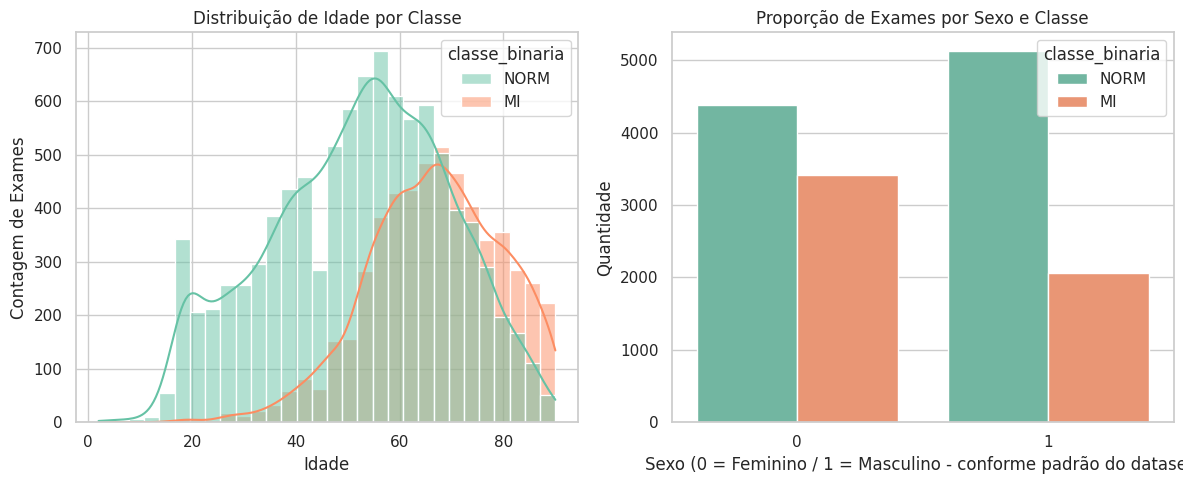


--- Estatísticas descritivas de idade por classe ---
                 count       mean        std   min   25%   50%   75%   max
classe_binaria                                                            
MI              5468.0  66.787125  12.870279  15.0  58.0  67.0  76.0  90.0
NORM            9513.0  52.172816  17.325854   2.0  40.0  54.0  65.0  90.0


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=df_binario, x='age', hue='classe_binaria', bins=30, kde=True, palette='Set2', common_norm=False)
plt.title('Distribuição de Idade por Classe')
plt.xlabel('Idade')
plt.ylabel('Contagem de Exames')

plt.subplot(1, 2, 2)
sns.countplot(data=df_binario, x='sex', hue='classe_binaria', palette='Set2')
plt.title('Proporção de Exames por Sexo e Classe')
plt.xlabel('Sexo (0 = Feminino / 1 = Masculino - conforme padrão do dataset)')
plt.ylabel('Quantidade')

plt.tight_layout()
plt.show()

print("\n--- Estatísticas descritivas de idade por classe ---")
print(df_binario.groupby('classe_binaria')['age'].describe())

##4 - Análise exploratória: classes por paciente

A tarefa também precisa ser analisada no nível do paciente, não apenas no nível do exame. Isso é importante porque um mesmo paciente pode possuir vários ECGs.


Distribuição das classes por paciente:
classe_paciente
NORM     8766
MI       4540
AMBOS     129
Name: count, dtype: int64


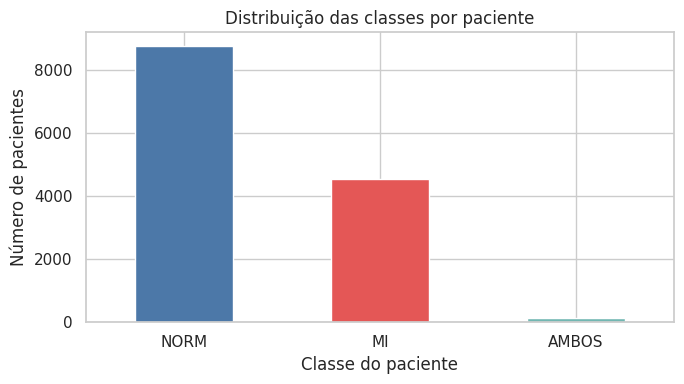

In [22]:
# Classe(s) encontrada(s) em cada paciente
classes_por_paciente = (
    df_binario.groupby(["patient_id", "classe_binaria"])
    .size()
    .unstack(fill_value=0)
)
for coluna in ["NORM", "MI"]:
    if coluna not in classes_por_paciente.columns:
        classes_por_paciente[coluna] = 0

classes_por_paciente["classe_paciente"] = np.select(
    [
        (classes_por_paciente["NORM"] > 0) & (classes_por_paciente["MI"] == 0),
        (classes_por_paciente["MI"] > 0) & (classes_por_paciente["NORM"] == 0),
        (classes_por_paciente["NORM"] > 0) & (classes_por_paciente["MI"] > 0),
    ],
    ["NORM", "MI", "AMBOS"],
    default="SEM_CLASSE"
)

print("Distribuição das classes por paciente:")
print(classes_por_paciente["classe_paciente"].value_counts())

classes_por_paciente["classe_paciente"].value_counts().reindex(
    ["NORM", "MI", "AMBOS"], fill_value=0
).plot(kind="bar", figsize=(7, 4), color=["#4c78a8", "#e45756", "#72b7b2"])
plt.title("Distribuição das classes por paciente")
plt.xlabel("Classe do paciente")
plt.ylabel("Número de pacientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5 - Hipótese Científica

Hipotetiza-se que sinais eletrocardiográficos (ECG) de 12 derivações contêm padrões morfológicos e temporais discriminativos suficientes para permitir que modelos de aprendizado de máquina classifiquem com alta precisão registros normais (NORM) e de infarto do miocárdio (MI). Além disso, assume-se que a separação rigorosa por paciente na divisão dos conjuntos de treino, validação e teste é indispensável para evitar o vazamento de dados (data leakage), garantindo a capacidade de generalização real do modelo para novos indivíduos. Por fim, prevê-se que a inclusão de covariáveis clínicas, como a idade do paciente — cuja média é maior nos casos de infarto (conforme a estatística descritiva) —, possa complementar a capacidade preditiva do pipeline.

## 6 - Divisão dos Dados por Paciente
Para evitar o vazamento de dados (data leakage) e garantir a capacidade de generalização do modelo para novos indivíduos, a divisão dos conjuntos de treino, validação e teste foi realizada estritamente ao nível do paciente (patient_id). No dataset PTB-XL, um mesmo indivíduo pode possuir múltiplos registros de ECG ao longo do tempo. Uma divisão aleatória por exames faria com que sinais do mesmo paciente estivessem presentes simultaneamente no treino e no teste, levando a uma avaliação superestimada do desempenho do modelo.

Dessa forma, isolaram-se os identificadores únicos de cada paciente e aplicou-se a separação nas proporções de 70% para treino, 15% para validação e 15% para teste. Com essa abordagem, garante-se que nenhum paciente do conjunto de teste ou validação tenha sido previamente 'visto' pelo algoritmo durante a fase de treinamento.

In [23]:
from sklearn.model_selection import train_test_split

pacientesUnicos = df_binario['patient_id'].unique()

pacientesTreinoVal, pacientesTeste = train_test_split(
    pacientesUnicos,
    test_size=0.15,
    random_state=42
)

pacientesTreino, pacientesVal = train_test_split(
    pacientesTreinoVal,
    test_size=0.1764,
    random_state=42
)

df_train = df_binario[df_binario['patient_id'].isin(pacientesTreino)].copy()
df_val = df_binario[df_binario['patient_id'].isin(pacientesVal)].copy()
df_test = df_binario[df_binario['patient_id'].isin(pacientesTeste)].copy()

print(f"--- Resumo da Divisão por Paciente ---")
print(f"Treino     -> Exames: {df_train.shape[0]} | Pacientes únicos: {df_train['patient_id'].nunique()}")
print(f"Validação  -> Exames: {df_val.shape[0]} | Pacientes únicos: {df_val['patient_id'].nunique()}")
print(f"Teste      -> Exames: {df_test.shape[0]} | Pacientes únicos: {df_test['patient_id'].nunique()}")

--- Resumo da Divisão por Paciente ---
Treino     -> Exames: 10513 | Pacientes únicos: 9404
Validação  -> Exames: 2258 | Pacientes únicos: 2015
Teste      -> Exames: 2210 | Pacientes únicos: 2016


### Verificação da separação por paciente

A divisão é por `patient_id`. Portanto, o mesmo paciente não pode aparecer em treino, validação e teste. A divisão foi feita de forma aleatória e reprodutível, mas não é uma estratificação formal das classes.


In [24]:
assert set(df_train["patient_id"]).isdisjoint(set(df_val["patient_id"]))
assert set(df_train["patient_id"]).isdisjoint(set(df_test["patient_id"]))
assert set(df_val["patient_id"]).isdisjoint(set(df_test["patient_id"]))
print("OK: nenhum paciente aparece em mais de um conjunto.")


OK: nenhum paciente aparece em mais de um conjunto.


In [25]:
# Download de apenas um ECG de exemplo para visualizar as 12 derivações.
import os
# Isso evita baixar toda a base no primeiro ciclo exploratório.
from urllib.request import urlretrieve

base_dir = '/content/ptbxl_sample/'
base_url = 'https://physionet.org/files/ptb-xl/1.0.3/'
example_id = int(df_train.index[0])
caminho_relativo = str(df_ptbxl.loc[example_id, 'filename_lr'])
local_base = os.path.join(base_dir, caminho_relativo)
os.makedirs(os.path.dirname(local_base), exist_ok=True)

for extensao in ['.dat', '.hea']:
    arquivo_local = local_base + extensao
    arquivo_remoto = base_url + caminho_relativo + extensao
    if not os.path.exists(arquivo_local):
        print(f'Baixando {arquivo_remoto}')
        urlretrieve(arquivo_remoto, arquivo_local)

print(f'ECG de exemplo disponível em: {local_base}')


ECG de exemplo disponível em: /content/ptbxl_sample/records100/00000/00001_lr


## 7 - Carregamento dos sinais de ECG
Além dos metadados clínicos, a pipeline metodológica prevê o acesso direto aos sinais eletrocardiográficos brutos armazenados nos arquivos de formato wfdb (.dat e .hea) associados a cada registo. Utilizando a biblioteca wfdb, validou-se a rotina de leitura para extrair a matriz de sinais multiderivação (12 derivações) de cada exame. Esta etapa é fundamental para a posterior extração de características estruturadas ou para alimentar diretamente arquiteturas de Redes Neuronais Convolucionais (CNNs) voltadas à detecção de infarto.

### Função reutilizável de carregamento

A função abaixo centraliza a leitura de um exame. Ela verifica o identificador, monta o caminho do arquivo e confirma que o sinal possui 12 derivações.


In [26]:
def carregar_ecg(ecg_id, metadados, diretorio_base, resolucao='lr'):
    if ecg_id not in metadados.index:
        raise KeyError(f'ecg_id não encontrado: {ecg_id}')
    if resolucao not in ['lr', 'hr']:
        raise ValueError("resolucao deve ser 'lr' ou 'hr'")
    coluna = f'filename_{resolucao}'
    caminho = os.path.join(str(diretorio_base), str(metadados.loc[ecg_id, coluna]))
    sinal, metadados_sinal = wfdb.rdsamp(caminho)
    if sinal.ndim != 2 or sinal.shape[1] != 12:
        raise ValueError(f'Formato inesperado: {sinal.shape}')
    return sinal, metadados_sinal


In [27]:
base_dir = '/content/ptbxl_sample/'

sinal, metadata_sinal = carregar_ecg(example_id, df_ptbxl, base_dir, resolucao='lr')

print("--- Sucesso ao carregar o sinal do ECG! ---")
print(f"Formato (Shape) da matriz do sinal: {sinal.shape}")
print(f"Frequência de amostragem (Hz): {metadata_sinal['fs']}")
print(f"Derivações presentes: {metadata_sinal['sig_name']}")

--- Sucesso ao carregar o sinal do ECG! ---
Formato (Shape) da matriz do sinal: (1000, 12)
Frequência de amostragem (Hz): 100
Derivações presentes: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


### Gráfico das 12 derivações

O gráfico abaixo mostra o sinal ECG lido, com uma linha para cada uma das 12 derivações.


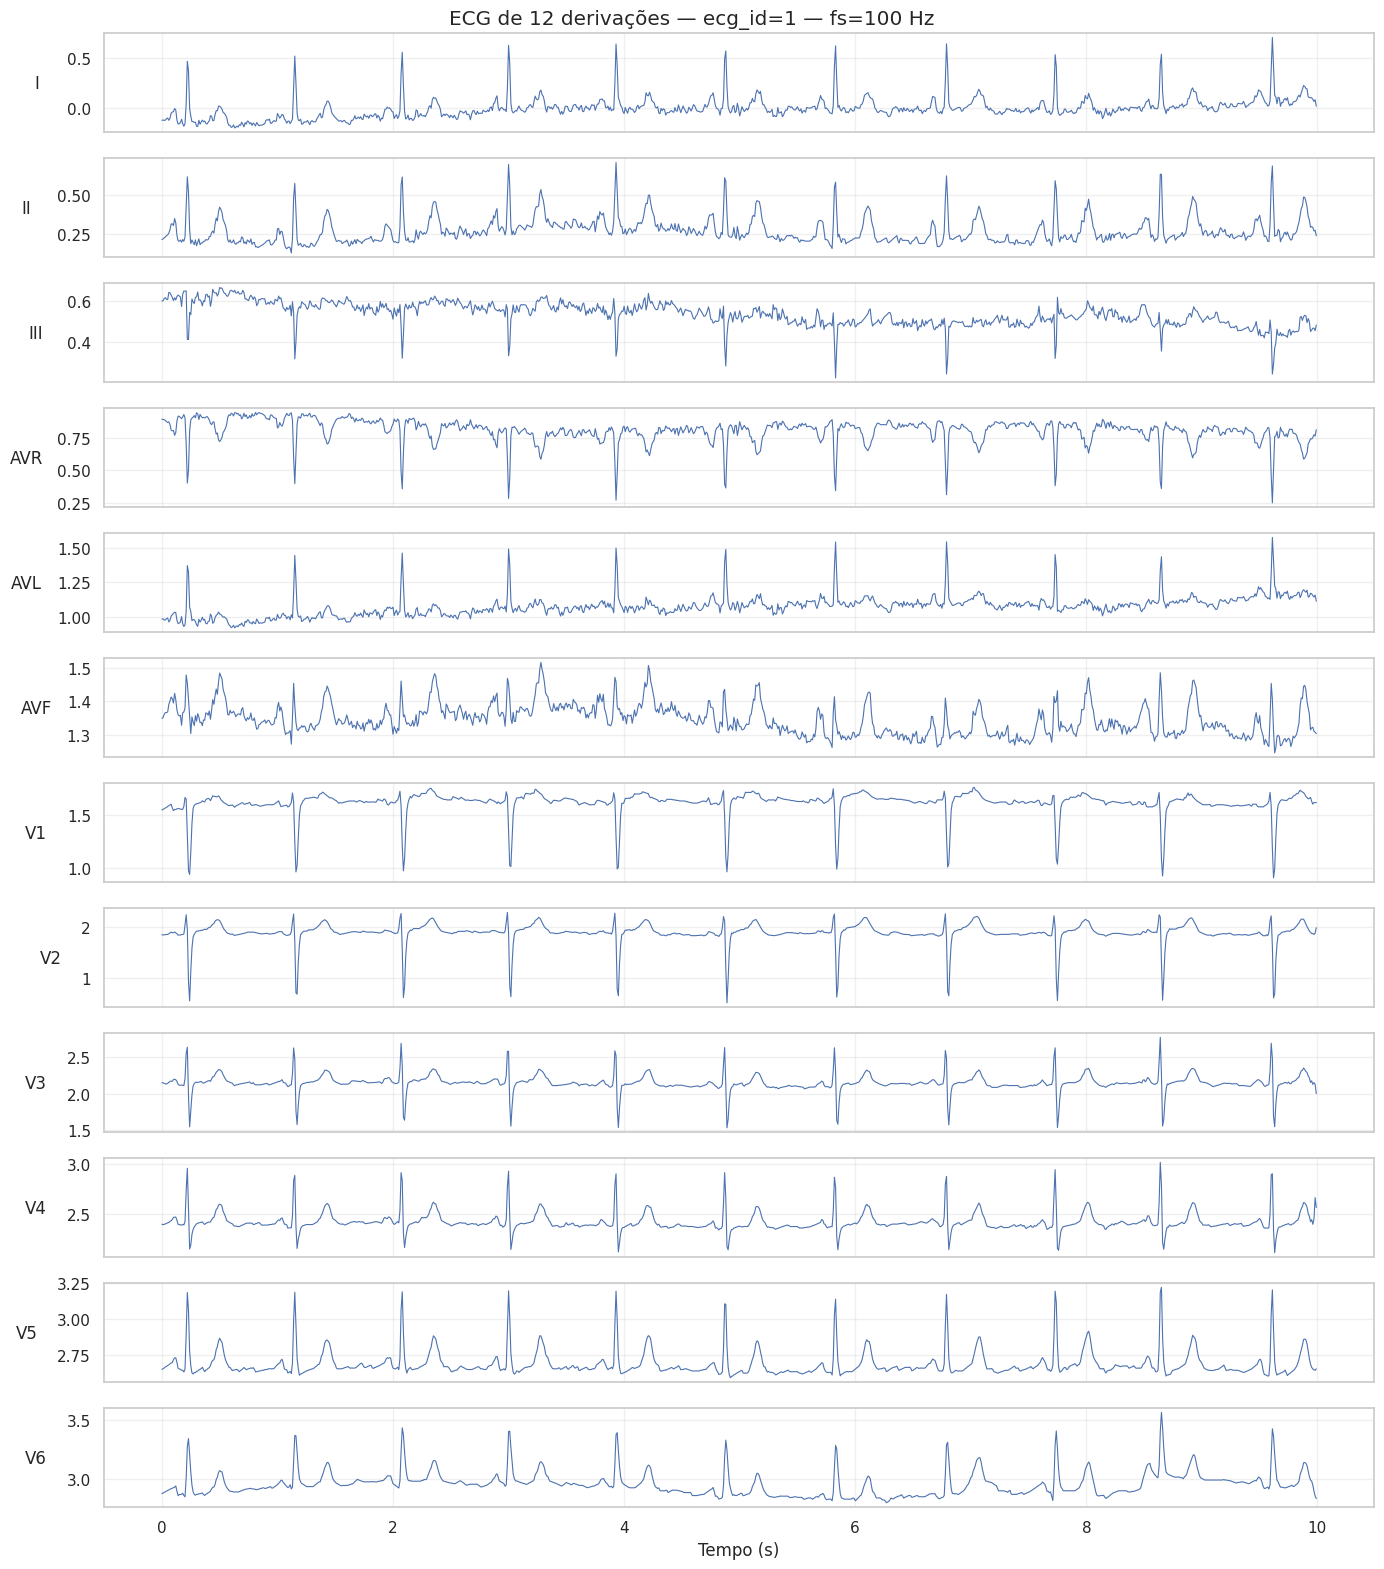

In [28]:
fs = metadata_sinal['fs']
nomes_derivacoes = metadata_sinal['sig_name']
tempo = np.arange(sinal.shape[0]) / fs
offset = 2.5 * np.nanstd(sinal)

fig, eixos = plt.subplots(12, 1, figsize=(14, 16), sharex=True)
for i, eixo in enumerate(eixos):
    eixo.plot(tempo, sinal[:, i] + i * offset, linewidth=0.8)
    eixo.set_ylabel(nomes_derivacoes[i], rotation=0, labelpad=22, va='center')
    eixo.grid(True, alpha=0.3)
eixos[-1].set_xlabel('Tempo (s)')
fig.suptitle(f'ECG de 12 derivações — ecg_id={example_id} — fs={fs} Hz')
plt.tight_layout()
plt.show()


## 8 - Pré-processamento e Normalização dos Sinais
Com o objetivo de condicionar os sinais brutos para o treinamento das redes neurais, aplicou-se uma rotina de pré-processamento nos dados eletrocardiográficos. Os sinais de cada derivação foram submetidos à padronização via Z-score normalization, garantindo média nula ($\mu = 0$) e variância unitária ($\sigma = 1$). Essa etapa mitiga discrepâncias de amplitude causadas por variações de impedância na aquisição dos exames, estabilizando o gradiente de aprendizagem e acelerando a convergência dos algoritmos de classificação.

In [29]:
import numpy as np

def preprocessar_sinal(sinal):
    """
    Realiza a normalização Z-score por derivação para padronizar
    a amplitude dos sinais de ECG.
    """
    sinal = np.nan_to_num(sinal)

    media = np.mean(sinal, axis=0)
    desvio = np.std(sinal, axis=0)

    sinal_normalizado = (sinal - media) / (desvio + 1e-8)

    return sinal_normalizado

sinal_processado = preprocessar_sinal(sinal)

print("--- Sinal Pré-processado ---")
print(f"Formato original: {sinal.shape}")
print(f"Formato após pré-processamento: {sinal_processado.shape}")
print(f"Média após normalização: {np.mean(sinal_processado):.4f} (deve ser ~0)")
print(f"Desvio padrão após normalização: {np.std(sinal_processado):.4f} (deve ser ~1)")

--- Sinal Pré-processado ---
Formato original: (1000, 12)
Formato após pré-processamento: (1000, 12)
Média após normalização: 0.0000 (deve ser ~0)
Desvio padrão após normalização: 1.0000 (deve ser ~1)


##9 - Testes mínimos da etapa exploratória


In [30]:
# --- Rotulagem ---
assert rotular_tarefa_robusta({'scp_codes_dict': {'NORM': 100.0}}) == 'NORM'
assert rotular_tarefa_robusta({'scp_codes_dict': {'IMI': 100.0}}) == 'MI'
assert rotular_tarefa_robusta({'scp_codes_dict': {'INJAS': 35.0}}) == 'MI'
assert rotular_tarefa_robusta({'scp_codes_dict': {'NORM': 80.0, 'IMI': 50.0}}) == 'Outros'
assert rotular_tarefa_robusta({'scp_codes_dict': {'LVH': 100.0}}) == 'Outros'
assert set(df_binario['classe_binaria'].unique()) <= {'NORM', 'MI'}

# --- Idade ---
assert df_binario['age'].max() <= 90

# --- Carregamento: forma e dimensões ---
assert sinal.shape == (1000, 12)
assert metadata_sinal['fs'] == 100
assert len(metadata_sinal['sig_name']) == 12

try:
    carregar_ecg(-1, df_ptbxl, base_dir)
    raise AssertionError('Era esperado KeyError para ecg_id inexistente')
except KeyError:
    pass

try:
    carregar_ecg(example_id, df_ptbxl, base_dir, resolucao='xx')
    raise AssertionError('Era esperado ValueError para resolução inválida')
except ValueError:
    pass

# --- Normalização ---
assert sinal_processado.shape == sinal.shape
assert np.allclose(np.mean(sinal_processado, axis=0), 0, atol=1e-6)
assert np.allclose(np.std(sinal_processado, axis=0), 1, atol=1e-6)

print('Testes mínimos concluídos com sucesso.')

Testes mínimos concluídos com sucesso.
